Лабораторна робота 2. Бессараб, 4-9


---



# Завдання 1

**Був присутній на парі**

Обробка та нааліз даних про ВВП країн. Датасет було отримано з Вікіпедії з використанням бібілотеки Pandas.

In [9]:
import requests
import pandas as pd

url = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/131.0 Safari/537.36"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [10]:
tables = pd.read_html(response.text)

for i, table in enumerate(tables):
    print(i, table.shape)

0 (1, 1)
1 (1, 2)
2 (222, 4)
3 (14, 3)
4 (8, 2)
5 (9, 2)
6 (13, 2)
7 (2, 2)


/tmp/ipykernel_1236/3973610040.py:1: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(response.text)


1. Вивести перші 5 рядків датасета

In [11]:
df = tables[2]

df.head(5)

,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


[Текст ссылки](https://)2.	Визначити розмір датасета.

In [13]:
df.shape

(222, 4)

 3.	Визначити оптимальну кількість стовпців (видалити зайві, на власний розсуд).

In [20]:
df.columns

Index(['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]'], dtype='object')

In [21]:
df = df.drop(columns=['United Nations (2024)[7]'])

KeyError: "['United Nations (2024)[7]'] not found in axis"

In [22]:
print(df.columns)
print(df.shape)

Index(['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]'], dtype='object')
(222, 3)


4.	Замініть у таблиці значення "—" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [23]:
import numpy as np
df = df.replace("—", np.nan)
print(df.isna().sum())

Country/Territory       0
IMF (2026)[1]           0
World Bank (2025)[6]    0
dtype: int64


In [24]:
for col in df.columns[1:]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    df[col] = df[col].fillna(df[col].mean())

print(df.isna().sum())

Country/Territory       0
IMF (2026)[1]           0
World Bank (2025)[6]    0
dtype: int64


5. Ще раз вивести датасет

In [25]:
df

,Country/Territory,IMF (2026)[1],World Bank (2025)[6]
0,World,1.262953e+08,1.183502e+08
1,United States,3.238392e+07,3.076970e+07
2,China[n 1],2.085159e+07,1.949804e+07
3,Germany,5.452858e+06,5.050923e+06
4,Japan,4.379253e+06,4.435163e+06
...,...,...,...
217,Palau,3.770000e+02,3.450000e+02
218,Marshall Islands,3.420000e+02,3.080000e+02
219,Nauru,1.960000e+02,1.760000e+02
220,Montserrat,1.319229e+06,1.255590e+06


6.	Перевірити наявність дублікатів. При наявності видалити дублікати.

In [26]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


7.	Вивести описову статистику датасету describe()

---



In [27]:
df.describe()

,IMF (2026)[1],World Bank (2025)[6]
count,2.220000e+02,2.220000e+02
mean,1.319229e+06,1.255590e+06
std,8.838876e+06,8.288461e+06
min,6.500000e+01,5.700000e+01
25%,1.932375e+04,2.003400e+04
50%,1.039745e+05,9.986350e+04
75%,7.726678e+05,1.041520e+06
max,1.262953e+08,1.183502e+08


8. Визначте відхилення (різницю) між показниками IMF (2026) та World Bank (2025) для кожної країни. У яких країнах ці показники найбільше відрізняються (дати відповідь)?

In [28]:
df['Difference'] = abs(df['IMF (2026)[1]'] - df['World Bank (2025)[6]'])

df[['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]', 'Difference']].head()

,Country/Territory,IMF (2026)[1],World Bank (2025)[6],Difference
0,World,126295331.0,118350166.0,7945165.0
1,United States,32383920.0,30769700.0,1614220.0
2,China[n 1],20851593.0,19498039.0,1353554.0
3,Germany,5452858.0,5050923.0,401935.0
4,Japan,4379253.0,4435163.0,55910.0


In [29]:
df.nlargest(10, 'Difference')[['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]', 'Difference']]

,Country/Territory,IMF (2026)[1],World Bank (2025)[6],Difference
0,World,1.262953e+08,1.183502e+08,7.945165e+06
1,United States,3.238392e+07,3.076970e+07,1.614220e+06
2,China[n 1],2.085159e+07,1.949804e+07,1.353554e+06
197,Sint Maarten,1.319229e+06,1.888000e+03,1.317341e+06
146,Palestine[n 11][n 12],1.319229e+06,1.716700e+04,1.302062e+06
192,San Marino,2.417000e+03,1.255590e+06,1.253173e+06
179,Aruba,4.671000e+03,1.255590e+06,1.250919e+06
172,South Sudan,6.069000e+03,1.255590e+06,1.249521e+06
168,Yemen,7.435000e+03,1.255590e+06,1.248155e+06
159,Liechtenstein,9.442000e+03,1.255590e+06,1.246148e+06


Для кожної країни було визначено абсолютну різницю між показниками IMF (2026) та World Bank (2025). Найбільше відхилення серед країн спостерігається у United States — приблизно 1 614 220 млн доларів США, China — приблизно 1 353 554 млн доларів США, Sint Maarten — приблизно 1 317 341 млн доларів США, Palestine — приблизно 1 302 062 млн доларів США та San Marino — приблизно 1 253 173 млн доларів США.


9.	Обчисліть кореляцію між показниками IMF (2026), World Bank (2025) та United Nations (2024). Які пари змінних мають найвищу кореляцію?

In [30]:
df_corr = tables[2].copy()

df_corr = df_corr.replace("—", np.nan)

for col in df_corr.columns[1:]:
    df_corr[col] = pd.to_numeric(df_corr[col], errors="coerce")

df_corr = df_corr.dropna()

df_corr.corr(numeric_only=True)

,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
IMF (2026)[1],1.000000,0.999986,0.999966
World Bank (2025)[6],0.999986,1.000000,0.999982
United Nations (2024)[7],0.999966,0.999982,1.000000


In [32]:
corr = df_corr.corr(numeric_only=True)

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()

print(pairs.sort_values(ascending=False))

IMF (2026)[1]         World Bank (2025)[6]        0.999986
World Bank (2025)[6]  United Nations (2024)[7]    0.999982
IMF (2026)[1]         United Nations (2024)[7]    0.999966
dtype: float64


Найвищу кореляцію мають показники IMF (2026) та World Bank (2025), значення кореляції становить 0.999986.

Обчислити середнє значення за стовпцями

In [33]:
df[['IMF (2026)[1]', 'World Bank (2025)[6]']].mean()

,0
IMF (2026)[1],1.319229e+06
World Bank (2025)[6],1.255590e+06


11.	Обчисліть стандартне відхилення показників для кожної країни. Яка країна має найвищу варіативність у показниках між роками?

In [34]:
df['Std'] = df[['IMF (2026)[1]', 'World Bank (2025)[6]']].std(axis=1)

df[['Country/Territory', 'Std']].sort_values('Std', ascending=False).head(10)

,Country/Territory,Std
0,World,5.618080e+06
1,United States,1.141426e+06
2,China[n 1],9.571072e+05
197,Sint Maarten,9.315009e+05
146,Palestine[n 11][n 12],9.206970e+05
192,San Marino,8.861274e+05
179,Aruba,8.845336e+05
172,South Sudan,8.835451e+05
168,Yemen,8.825792e+05
159,Liechtenstein,8.811600e+05


Найвищу варіативність серед країн має United States — стандартне відхилення становить приблизно 1 141 426 млн доларів США.

12.	Визначення країни з найвищим та найнижчим показниками: Знайдіть країну з найвищим та найнижчим показниками у кожному з років (IMF (2026), World Bank (2025), United Nations (2024)).

In [35]:
df_years = tables[2].copy()

for col in df_years.columns[1:]:
    df_years[col] = pd.to_numeric(df_years[col], errors='coerce')

for col in df_years.columns[1:]:
    max_idx = df_years[col].idxmax()
    min_idx = df_years[col].idxmin()

    print(col)
    print("Найвищий показник:", df_years.loc[max_idx, 'Country/Territory'], df_years.loc[max_idx, col])
    print("Найнижчий показник:", df_years.loc[min_idx, 'Country/Territory'], df_years.loc[min_idx, col])
    print()

IMF (2026)[1]
Найвищий показник: World 126295331.0
Найнижчий показник: Tuvalu 65.0

World Bank (2025)[6]
Найвищий показник: World 118350166.0
Найнижчий показник: Tuvalu 57.0

United Nations (2024)[7]
Найвищий показник: World 111565144.0
Найнижчий показник: Tuvalu 56.0



13.	Побудуйте гістограму для розподілу показників IMF (2026) серед всіх країн. Який вигляд має розподіл? Чи є країни, що виділяються?

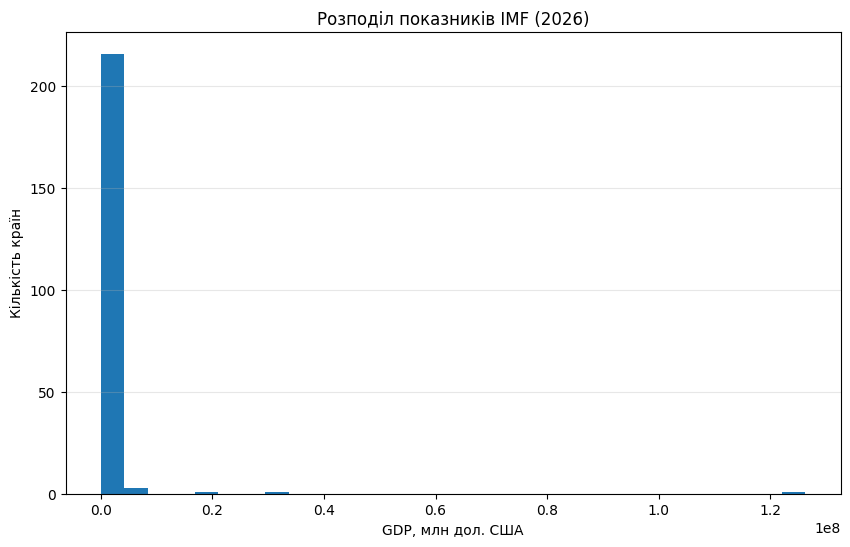

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['IMF (2026)[1]'], bins=30)
plt.xlabel('GDP, млн дол. США')
plt.ylabel('Кількість країн')
plt.title('Розподіл показників IMF (2026)')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [42]:
df.nlargest(5, 'IMF (2026)[1]')[['Country/Territory', 'IMF (2026)[1]']]

,Country/Territory,IMF (2026)[1]
0,World,126295331.0
1,United States,32383920.0
2,China[n 1],20851593.0
3,Germany,5452858.0
4,Japan,4379253.0


14.	Розрахуйте частку кожної країни в загальному значенні для кожного року (IMF (2026), World Bank (2025), United Nations (2024)).
 Як змінюються частки країн з часом (дати відповідь)?

In [44]:
df_share = tables[2].copy()

for col in df_share.columns[1:]:
    df_share[col] = pd.to_numeric(df_share[col], errors='coerce')

for col in df_share.columns[1:]:
    df_share[col + ' Share (%)'] = df_share[col] / df_share[col].sum() * 100

df_share.head()

,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7],IMF (2026)[1] Share (%),World Bank (2025)[6] Share (%),United Nations (2024)[7] Share (%)
0,World,126295331.0,118350166.0,111565144.0,50.122608,50.405656,50.179237
1,United States,32383920.0,30769700.0,29298000.0,12.852150,13.104898,13.177514
2,China[n 1],20851593.0,19498039.0,18743802.0,8.275335,8.304268,8.430498
3,Germany,5452858.0,5050923.0,4659929.0,2.164066,2.151202,2.095921
4,Japan,4379253.0,4435163.0,4026211.0,1.737986,1.888948,1.810890


In [46]:
df_share[['Country/Territory', 'IMF (2026)[1] Share (%)',
          'World Bank (2025)[6] Share (%)',
          'United Nations (2024)[7] Share (%)']].sort_values(
    'IMF (2026)[1] Share (%)', ascending=False
).head(10)

,Country/Territory,IMF (2026)[1] Share (%),World Bank (2025)[6] Share (%),United Nations (2024)[7] Share (%)
0,World,50.122608,50.405656,50.179237
1,United States,12.852150,13.104898,13.177514
2,China[n 1],8.275335,8.304268,8.430498
3,Germany,2.164066,2.151202,2.095921
4,Japan,1.737986,1.888948,1.810890
5,United Kingdom,1.692561,1.704713,1.657818
6,India,1.648270,1.684900,1.777621
7,France,1.427176,1.433723,1.421489
8,Italy,1.086690,1.086715,1.070836
9,Russia,1.054261,1.090869,0.977535


Найбільшу частку серед окремих країн у всіх трьох джерелах мають United States та China. Частка United States становить приблизно 12,85% за даними IMF, 13,10% за даними World Bank та 13,18% за даними United Nations. Частка China становить відповідно 8,28%, 8,30% та 8,43%.

Загалом частки найбільших економік змінюються незначно. У деяких країн частка трохи збільшується або зменшується залежно від джерела та року, але суттєвих змін у розподілі часток не спостерігається.

15.	Візуалізуйте зміни в показниках для кожної країни за три роки на графіку. Які країни показують стабільне зростання або спад (дати відповідь)?

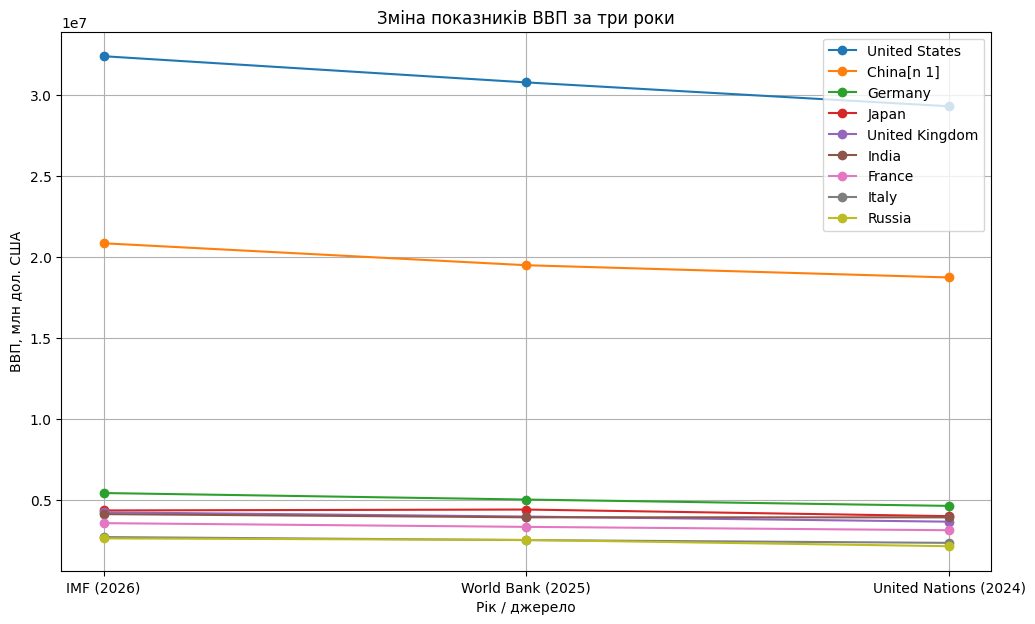

In [51]:
import matplotlib.pyplot as plt

countries = ['United States', 'China[n 1]', 'Germany', 'Japan', 'United Kingdom',
             'India', 'France', 'Italy', 'Russia']

plot_data = df_share[df_share['Country/Territory'].isin(countries)]

plt.figure(figsize=(12, 7))

for _, row in plot_data.iterrows():
    plt.plot(
        ['IMF (2026)', 'World Bank (2025)', 'United Nations (2024)'],
        [row['IMF (2026)[1]'], row['World Bank (2025)[6]'], row['United Nations (2024)[7]']],
        marker='o',
        label=row['Country/Territory']
    )

plt.xlabel('Рік / джерело')
plt.ylabel('ВВП, млн дол. США')
plt.title('Зміна показників ВВП за три роки')
plt.legend()
plt.grid(True)
plt.show()